# Call My BLEUff

24 rounds, 3 seats, 40 venue cards per deck, 5 references per card. One seat per round is honest; the producers crowned the highest corpus BLEU.

Plan: score the decks with the house scorer, read the texts, name the tricks, then judge each card the way a listener would (are the facts there, is anything said twice, is it English, is it just a cut-out of a reference) and count failing cards per deck.

In [1]:
import sys, re, math
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

TASK = Path("..") / "task_united_kingdom"
sys.path.insert(0, str(TASK))
from bleu import corpus_bleu, segment_stats, tokenize

refs = pd.read_csv(TASK / "references.csv")
panel = pd.read_csv(TASK / "panel.csv")
ref_map = refs.groupby(["round", "card"]).reference.apply(list).to_dict()
pd.set_option("display.width", 200, "display.max_colwidth", 200)
print(refs.shape, panel.shape)

(4800, 3) (2880, 4)


## 1. The house scorer

`bleu.py`: lower-cased word/punctuation tokens, BLEU-4, no smoothing, clipping against the single reference with the highest count, and the brevity penalty computed **once per deck** from summed lengths. So a short card costs nothing as long as other cards in the deck are long enough, and every n-gram lifted from any of the five references counts.

In [2]:
rows = []
for (rnd, seat), deck in panel.groupby(["round", "seat"]):
    res = corpus_bleu(list(deck.text), [ref_map[(rnd, c)] for c in deck.card])
    rows.append(dict(round=rnd, seat=seat, bleu=res["bleu"], bp=res["brevity_penalty"],
                     p1=res["precisions"][0], p4=res["precisions"][3],
                     out_len=res["output_length"], ref_len=res["reference_length"]))
decks = pd.DataFrame(rows)

def decode(seats):
    return "".join(chr(65 + 9 * (a - 1) + 3 * (b - 1) + (c - 1)) for a, b, c in zip(seats[0::3], seats[1::3], seats[2::3]))

bleu_pick = decks.loc[decks.groupby("round").bleu.idxmax()].sort_values("round").seat.tolist()
print("BLEU winners:", bleu_pick)
print("baseline word:", decode(bleu_pick))
decks.pivot(index="round", columns="seat", values=["bleu", "bp", "p4", "out_len"]).round(3)

BLEU winners: [3, 1, 1, 2, 1, 2, 1, 2, 2, 2, 1, 3, 1, 2, 1, 2, 3, 3, 1, 1, 1, 2, 3, 1]
baseline word: SKELDRAP


bleu                   bp                   p4               out_len                
seat       1      2      3      1      2      3      1      2      3       1       2       3
round                                                                                       
1      0.467  0.478  0.549  0.981  0.971  0.994  0.266  0.258  0.339   926.0   895.0   931.0
2      0.546  0.422  0.402  0.970  0.959  0.965  0.337  0.228  0.195   942.0   945.0   916.0
3      0.676  0.479  0.337  1.000  0.997  0.964  0.473  0.258  0.147   833.0   871.0   841.0
4      0.428  0.593  0.457  0.973  1.000  1.000  0.219  0.356  0.234   928.0   961.0   937.0
5      0.560  0.541  0.455  0.992  1.000  0.992  0.348  0.380  0.246   862.0  1166.0   897.0
6      0.366  0.472  0.381  0.964  0.983  0.974  0.161  0.254  0.190   826.0   871.0   876.0
7      0.582  0.391  0.407  1.000  1.000  0.922  0.364  0.178  0.235  1027.0   957.0   835.0
8      0.448  0.578  0.465  0.991  0.866  0.977  0.228  0.484  0.267   884.0   731.0   911.0
9      0.482  0.537  0.403  0.736  1.000  0.992  0.479  0.318  0.197   606.0   967.0   990.0
10     0.418  0.566  0.444  1.000  0.995  0.985  0.207  0.341  0.225   917.0   914.0   915.0
11     0.551  0.407  0.470  0.958  1.000  1.000  0.350  0.213  0.289   885.0   980.0  1180.0
12     0.439  0.451  0.739  0.945  0.979  1.000  0.245  0.248  0.657   871.0   922.0  1241.0
13     0.590  0.432  0.540  1.000  1.000  1.000  0.368  0.220  0.382   959.0   999.0  1266.0
14     0.535  0.561  0.405  1.000  1.000  0.998  0.375  0.326  0.189  1317.0   869.0   880.0
15     0.600  0.399  0.419  1.000  1.000  0.904  0.394  0.174  0.263   958.0   926.0   713.0
16     0.476  0.574  0.436  0.966  1.000  1.000  0.259  0.347  0.233   893.0   961.0   935.0
17     0.372  0.475  0.517  0.981  1.000  0.918  0.179  0.262  0.356   935.0   933.0   755.0
18     0.434  0.442  0.585  1.000  1.000  1.000  0.251  0.209  0.357  1273.0   943.0   989.0
19     0.472  0.390  0.458  0.865  1.000  0.986  0.351  0.187  0.239   750.0   958.0   901.0
20     0.497  0.459  0.453  0.822  0.997  0.978  0.417  0.259  0.246   674.0   873.0   888.0
21     0.497  0.462  0.432  0.981  0.979  1.000  0.279  0.255  0.214   898.0   878.0   969.0
22     0.503  0.541  0.519  1.000  0.999  0.995  0.345  0.307  0.314  1300.0   891.0   936.0
23     0.484  0.341  0.784  0.973  0.989  1.000  0.269  0.142  0.708   938.0   975.0  1344.0
24     0.497  0.451  0.441  0.862  0.965  0.995  0.384  0.246  0.236   745.0   906.0   942.0

## 2. Looking at the texts

In [3]:
def show_card(rnd, card):
    print(f"round {rnd}, card {card}")
    for r in ref_map[(rnd, card)]:
        print("   ref   ", r)
    for _, x in panel[(panel["round"] == rnd) & (panel.card == card)].iterrows():
        print(f"   seat {x.seat}", x.text)

show_card(1, 1); print(); show_card(9, 2)

round 1, card 1
   ref    The Punter is an average-priced coffee that serves Japanese food. Located near Café Sicilia, this family-friendly location receives a rating of 1 out of 5 stars from customers.
   ref    There is a 1 out of 5 rated coffee shop near Café Sicilia that offer Japanese food with moderate price. The name is The Punter and their place are also kids friendly
   ref    The coffee shop The Punter is located near to Café Sicilia. This family-friendly shop serves average-priced Japanese food. Customers give this coffee shop 1 star out of 5.
   ref    The Punter is a 1 out of 5 rated coffee shop located near Café Sicilia. They sell a moderate price Japanese food and the location are kids friendly
   ref    A kids friendly, Japanese coffee shop named, The Punter, with a moderate price range. It is near the Café Sicilia with a 1 out of 5 customer rating.
   seat 1 The Punter is a mid range Japanese coffee shop with low customer ratings. It is family friendly and is located n

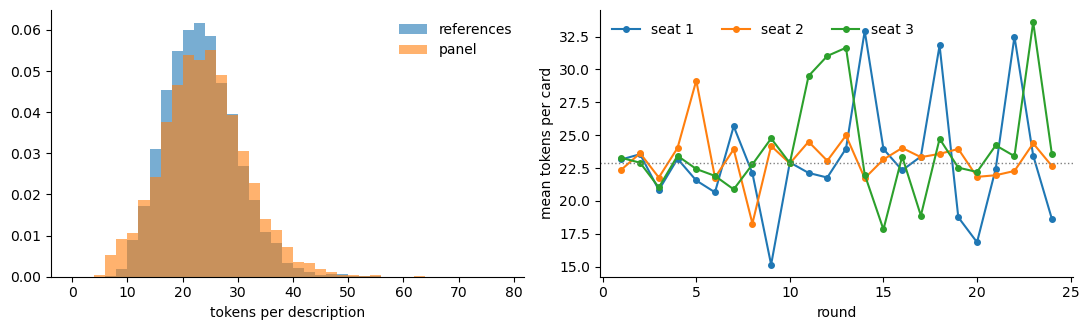

In [4]:
panel["ntok"] = panel.text.map(lambda t: len(tokenize(t)))
refs["ntok"] = refs.reference.map(lambda t: len(tokenize(t)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(refs.ntok, bins=range(0, 80, 2), alpha=.6, density=True, label="references")
ax[0].hist(panel.ntok, bins=range(0, 80, 2), alpha=.6, density=True, label="panel")
ax[0].set_xlabel("tokens per description"); ax[0].legend(frameon=False)
dl = panel.groupby(["round", "seat"]).ntok.mean().unstack()
for s in dl:
    ax[1].plot(dl.index, dl[s], "o-", ms=4, label=f"seat {s}")
ax[1].axhline(refs.ntok.mean(), color="grey", ls=":", lw=1)
ax[1].set_xlabel("round"); ax[1].set_ylabel("mean tokens per card"); ax[1].legend(frameon=False, ncol=3)
for a in ax: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

Deck lengths already split: some decks run ~35-50% longer than the references, some ~20-35% shorter, most sit near 1. Reading them, four tricks show up:

* **cropping** - a reference copied word for word and cut off mid-sentence ("... It has a customer rating of 3 out.");
* **padding** - a second description bolted on: reference sentences appended or a dangling "It is ..." sentence prepended, facts said twice;
* **splicing** - fragments of the five references stitched together; n-grams survive, grammar and sometimes the facts do not;
* **omitting** - short, safe sentences that drop most of the card ("Near Ranch is The Cricketers."), with a stray stutter ("more than more than £30").

All of them help BLEU: cropped and omitted cards carry only high-precision n-grams and the deck-level brevity penalty absorbs them; padding raises the matched n-gram count and the length; splicing keeps reference 4-grams without needing a sentence.

## 3. Listener checks

In [5]:
NAMES = ["Raja Indian Cuisine", "The Rice Boat", "The Wrestlers", "The Portland Arms", "The Cricketers", "Wildwood",
         "The Mill", "Ranch", "The Golden Curry", "Café Rouge", "Zizzi", "All Bar One", "The Vaults", "The Bakers",
         "Blue Spice", "Loch Fyne", "Café Brazil", "The Punter", "Aromi", "Cocum", "Alimentum", "Café Sicilia",
         "Rainbow Vegetarian Café", "Crowne Plaza Hotel", "Crown Plaza Hotel", "Cotto", "Fitzbillies", "Yippee Noodle Bar",
         "The Waterman", "Express by Holiday Inn", "Clowns", "Strada", "Giraffe", "The Phoenix", "Clare Hall",
         "Browns Cambridge", "The Cambridge Blue", "Café Adriatic", "Green Man", "The Plough", "The Sorrento",
         "The Olive Grove", "The Twenty Two", "Midsummer House", "The Golden Palace", "Avalon", "The Dumpling Tree",
         "Bibimbap House", "The Eagle", "Burger King", "Travellers Rest Beefeater", "Taste of Cambridge"]
NAMES = sorted(NAMES, key=len, reverse=True)

SLOTS = {
    "type": {"coffee shop": r"coffee|\bcaf[eé]\b", "pub": r"\bpub\b|\bbar\b"},
    "food": {"japanese": r"japan|sushi", "italian": r"ital|pasta|pizza", "french": r"french",
             "english": r"english|british", "chinese": r"chinese", "indian": r"indian|curry",
             "fast food": r"fast food|burger|fries|take ?out|take ?away"},
    "price": {
        "cheap": r"cheap|low[ -]?pric|low[ -]?cost|inexpensive|affordabl|budget|less than (?:£|l)?20|under (?:£|l)?20|low price range|bargain|value for money",
        "moderate": r"moderate(?:ly)?[ -]?pric|moderate price|price range (?:is|of) moderate|average[ -]?pric|mid[ -]?(?:range|pric|level)|medium[ -]?pric|20 ?(?:-|to) ?(?:£)?25|reasonabl|average cost|price range is average|moderate cost",
        "high": r"(?<!in)expensive|high[ -]?(?:pric|cost|end)|higher[ -]?pric|pricey|pricy|costly|more than (?:£|l)?30|over (?:£|l)?30|upscale|high price range|price range is high|30 euros"},
    "rating": {
        "low": r"\b1 out of 5|(?<!of )\bone[ -]star|(?<!of )\b1[ -]star|low(?:ly)?[ -]?(?:customer )?rat|poor(?:ly)?|bad(?:ly)? |low reviews|rated low|not (?:very )?(?:well|highly) rated|1 of 5|one out of five",
        "average": r"\b3 out of 5|(?<!of )\bthree[ -]star|(?<!of )\b3[ -]star|average (?:customer )?rat|averagely rated|rated average|average rated|mediocre|3 of 5|three out of five|moderate(?:ly)? (?:customer )?rat",
        "high": r"\b5 out of 5|(?<!of )\bfive[ -]star|(?<!of )\b5[ -]star|high(?:ly)?[ -]?(?:customer )?rat|excellent|great (?:customer )?rat|top rated|well rated|rated high|5 of 5|five out of five|rated highly"},
    "area": {"riverside": r"river", "city centre": r"city cent|centre of|center of|downtown|centre"},
    "family": {
        "no": r"not (?:a )?(?:family|kid|child)|\bnon[ -]?(?:family|kid|child)|\bno (?:kids|children|families)|adults? only|\badult|isn't (?:family|kid|child)|not for (?:the whole )?famil|not suitable for (?:kids|children|famil)|not .{0,25}(?:family|kid|child)[ -]?friendly|(?:does not|doesn't|don't|do not) (?:allow|welcome|cater)|no famil",
        "yes": r"famil|\bkid|child"},
}

def facts(text):
    low, names = text.lower(), set()
    for n in NAMES:
        k = n.lower(); short = k[4:] if k.startswith("the ") else k
        key = short.replace("crown plaza", "crowne plaza")
        if re.search(r"\b" + re.escape(short) + r"\b", low):
            names.add(key); low = re.sub(r"\b" + re.escape(short) + r"\b", " ", low)
    low = re.sub(r"\s+", " ", low.replace("-", " "))
    out = {"names": names}
    for slot, vals in SLOTS.items():
        hit = {v for v, pat in vals.items() if re.search(pat, low)}
        out[slot] = {"no"} if slot == "family" and "no" in hit else hit
    return out

def consensus(ref_facts, k=3):
    keys = []
    for slot in ["names", *SLOTS]:
        vals = [v for f in ref_facts for v in f[slot]]
        keys += [(slot, v) for v in set(vals) if vals.count(v) >= k]
    return keys

def missing(text, ref_facts):
    f = facts(text)
    return [(s, v) for s, v in consensus(ref_facts) if v not in f[s]]

def unsupported(text, ref_facts):
    f = facts(text)
    bad = [("names", n) for n in f["names"] - set().union(*[r["names"] for r in ref_facts])]
    for slot in SLOTS:
        union = set().union(*[r[slot] for r in ref_facts])
        if union and not (slot == "type" and sum(bool(r[slot]) for r in ref_facts) < 2):
            bad += [(slot, v) for v in f[slot] - union]
    return bad

def sents(t):
    return [s for s in re.split(r"(?<=[.!?])\s+", t.strip()) if s]

def restated(text):
    seen, dup = set(), 0
    for s in sents(text):
        f = facts(s); vals = {(k, v) for k in f if k not in ("names", "type") for v in f[k]}
        dup += len(vals & seen); seen |= vals
    return dup

def cropped(text, ref_texts):
    t = tokenize(text); t = t[:-1] if t[-1] in ".!?" else t
    for r in ref_texts:
        rt = tokenize(r)
        if len(t) <= 0.85 * len(rt) and any(rt[i:i + len(t)] == t for i in range(len(rt) - len(t) + 1)):
            return True
    return False

def stutter(text):
    t = tokenize(text)
    return sum(t[i:i + k] == t[i + k:i + 2 * k] for k in (2, 3, 4) for i in range(len(t) - 2 * k + 1))

Fluency: a trigram model (absolute discounting) trained on all 4,800 references **except the card being judged**, so a spliced card cannot borrow its own references' n-grams. Mean log2-probability per token.

In [6]:
def lm_tokens(t):
    return ["<s>", "<s>"] + tokenize(t) + ["</s>"]

def ngram_counts(texts):
    c = [Counter(), Counter(), Counter()]
    for t in texts:
        w = lm_tokens(t)
        for i in range(2, len(w)):
            c[0][w[i]] += 1; c[1][(w[i-1], w[i])] += 1; c[2][(w[i-2], w[i-1], w[i])] += 1
    return c

def histories(c2, c3):
    h2, f2, h3, f3 = Counter(), Counter(), Counter(), Counter()
    for (a, b), n in c2.items(): h2[a] += n; f2[a] += 1
    for (a, b, x), n in c3.items(): h3[(a, b)] += n; f3[(a, b)] += 1
    return h2, f2, h3, f3

ALL = ngram_counts(refs.reference)
ALL_H = histories(ALL[1], ALL[2])
N_ALL, V = sum(ALL[0].values()), len(ALL[0]) + 1
CARD = {k: ngram_counts(v) for k, v in ref_map.items()}

class TrigramLM:
    def __init__(self, key, d=0.75):
        self.b = CARD[key]; self.d = d
        self.N = N_ALL - sum(self.b[0].values())
        self.bh2, _, self.bh3, _ = histories(self.b[1], self.b[2])
        self.lost2 = Counter(a for (a, b), n in self.b[1].items() if ALL[1][(a, b)] == n)
        self.lost3 = Counter((a, b) for (a, b, x), n in self.b[2].items() if ALL[2][(a, b, x)] == n)

    def prob(self, u, v, w):
        a, b, (h2, f2, h3, f3) = ALL, self.b, ALL_H
        p = (a[0][w] - b[0][w] + 1) / (self.N + V)
        h = h2[v] - self.bh2[v]
        if h:
            p = max(a[1][(v, w)] - b[1][(v, w)] - self.d, 0) / h + self.d * (f2[v] - self.lost2[v]) / h * p
        h = h3[(u, v)] - self.bh3[(u, v)]
        if h:
            p = max(a[2][(u, v, w)] - b[2][(u, v, w)] - self.d, 0) / h + self.d * (f3[(u, v)] - self.lost3[(u, v)]) / h * p
        return p

    def score(self, text):
        w = lm_tokens(text)
        return float(np.mean([math.log2(self.prob(w[i-2], w[i-1], w[i])) for i in range(2, len(w))]))

LMS = {k: TrigramLM(k) for k in ref_map}

Each card is judged against its references:

| check | fails when |
|---|---|
| omit | ≥2 facts that at least 3 of the 5 references state (name, near, type, food, price, rating, area, family) are missing |
| pad | opens with a dangling "It/They ..." or restates a fact in a later sentence |
| crop | the text is a word-for-word cut of one reference, ≤85% of its length |
| garble | fluency below the 1st percentile of the references, or a repeated 2-4-gram ("more than more than") |

`wrong` (a value no reference supports) is computed too but kept out of the score: the references themselves disagree on area and price often enough to make it noisy.

Calibration: the same checks applied to every reference against the other four (and its own card left out of the language model).

In [7]:
def judge(text, key, ref_idx):
    rt = [ref_map[key][i] for i in ref_idx]
    rf = [REF_FACTS[key][i] for i in ref_idx]
    return dict(n_missing=len(missing(text, rf)), restated=restated(text),
                dangling=tokenize(text)[0] in ("it", "they"), crop=cropped(text, rt),
                lm=LMS[key].score(text), stutter=stutter(text), n_wrong=len(unsupported(text, rf)))

REF_FACTS = {k: [facts(x) for x in v] for k, v in ref_map.items()}
loo = pd.DataFrame([dict(round=k[0], card=k[1], ref=i, text=v[i], **judge(v[i], k, [j for j in range(5) if j != i]))
                    for k, v in ref_map.items() for i in range(5)])
LM_FLOOR = loo.lm.quantile(0.01)
card = pd.DataFrame([dict(round=x.round, card=x.card, seat=x.seat, text=x.text, **judge(x.text, (x.round, x.card), range(5)))
                     for x in panel.itertuples()])

def checks(d):
    return pd.DataFrame({"omit": d.n_missing >= 2,
                         "pad": d.dangling | (d.restated > 0),
                         "crop": d.crop,
                         "garble": (d.lm < LM_FLOOR) | (d.stutter > 0),
                         "wrong": d.n_wrong > 0}, index=d.index)

C, C_loo = checks(card), checks(loo)
SCORE = ["omit", "pad", "crop", "garble"]
card = card.join(C.add_prefix("f_"))
card["fails"] = C[SCORE].any(axis=1)
print("share of references failing each check (vs the other four):")
print(C_loo.mean().round(3).to_string(), "\nany scored check:", C_loo[SCORE].any(axis=1).mean().round(3))

share of references failing each check (vs the other four):
omit      0.130
pad       0.008
crop      0.000
garble    0.010
wrong     0.057 
any scored check: 0.144


The guide's own writers often leave facts out (that is most of the reference failure rate); the panel's honest decks, as it turns out, never do. The other three checks are rare among references.

## 4. Examples of each trick

In [8]:
def example(mask, sort, n=2, asc=False):
    d = card[mask].sort_values(sort, ascending=asc).head(n)
    for x in d.itertuples():
        print(f"  R{x.round} seat {x.seat} card {x.card}: {x.text}")

print("crop (word-for-word cut of a reference):")
for x in card[card.f_crop].sort_values(["round", "card"]).iloc[[0, 5]].itertuples():
    print(f"  R{x.round} seat {x.seat} card {x.card}: {x.text}")
    print("     cut from:", [r for r in ref_map[(x.round, x.card)] if cropped(x.text, [r])][0])
print("\npad (second description bolted on):"); example(card.f_pad, "restated")
print("\nsplice (reference fragments stitched, low fluency):"); example(card.f_garble, "lm", asc=True)
print("\nomit (most facts dropped):"); example(card.f_omit, "n_missing")
print("\nstutter:"); example(card.stutter > 0, "stutter")
print("\nwrong facts (not scored):"); example(card.f_wrong & (card.lm < -4.5), "n_wrong")

crop (word-for-word cut of a reference):
  R3 seat 2 card 7: The Vaults is a pub near Café Adriatic.
     cut from: The Vaults is a pub near Café Adriatic with a high customer rating and prices over £30.
  R7 seat 3 card 16: The Golden Palace is a pub in the riverside area.
     cut from: The Golden Palace is a pub in the riverside area. it is located near the Rainbow Vegetarian Café. The Golden Palace's average price is more than £30.

pad (second description bolted on):
  R5 seat 2 card 26: It is higher priced and suitable for families. Located on the riverside, near Burger King, The Eagle is a high priced English coffee shop with moderate ratings and a family friendly atmosphere. This coffee shop is family friendly and rated three stars.
  R18 seat 1 card 32: There is kids-friendly Fast food restaurant rated 1 out of 5 named The Rice Boat at the riverside. The Rice Boat at the riverside is kids-friendly Fast food restaurant rated 1 out of 5.

splice (reference fragments stitched, lo

In [9]:
seg = pd.DataFrame([segment_stats(x.text, ref_map[(x.round, x.card)]) for x in card.itertuples()])
card["p4"] = seg.matched.str[3] / seg.total.str[3].clip(lower=1)
card["len_ratio"] = seg.out_len / seg.ref_len
kind = np.select([card.f_crop, card.f_omit, card.f_pad, card.f_garble], ["crop", "omit", "pad", "garble"], "clean")
card.groupby(kind)[["p4", "len_ratio"]].agg(["mean", "size"]).round(3)

p4       len_ratio      
         mean  size      mean  size
clean   0.247  2250     1.010  2250
crop    0.874   119     0.620   119
garble  0.119     7     1.040     7
omit    0.283   280     0.854   280
pad     0.477   224     1.223   224

What BLEU gets for each trick, per card: cropped cards have by far the highest 4-gram precision; omitted cards are short and precise; padded cards are long and keep their precision; spliced cards keep reference n-grams without being sentences.

Two details of the scorer make short cards cheap. The reference length of a card is its *closest* reference, so a short card is measured against the shortest reference; and the penalty is paid once per deck. The heaviest cropper (round 9, seat 1) writes 606 tokens against 792 and pays BP 0.74, but its 4-gram precision is 0.48 against ~0.2-0.3 for complete decks, so its BLEU still beats the honest deck.

## 5. Decks: failing cards per seat

In [10]:
fails = card.groupby(["round", "seat"]).fails.sum().unstack()
by_check = card.groupby(["round", "seat"])[[f"f_{c}" for c in SCORE + ["wrong"]]].sum()
srt = np.sort(fails.values, axis=1)
verdict = pd.DataFrame({"honest_seat": fails.idxmin(axis=1), "honest_fails": srt[:, 0],
                        "next_best_fails": srt[:, 1], "margin": srt[:, 1] - srt[:, 0],
                        "bleu_winner": bleu_pick}, index=fails.index)
print(fails.T.to_string())
verdict

round  1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23  24
seat                                                                                                 
1       1   5  20   6   6  22   0   5  26  18   6   5   0  29   0   7   0  19  18  19   5  30   5  16
2       8   0   5   0  20   7   5  19   5   0   1   0   6   0   3   0   5   7   0   0  17   7   0   0
3      15  19   0  15   0   0  16   0   0   5  22  26  21   7  20  19  14   0   5   6   0   0  31   6


,honest_seat,honest_fails,next_best_fails,margin,bleu_winner
round,,,,,
1,1,1,8,7,3
2,2,0,5,5,1
3,3,0,5,5,1
4,2,0,6,6,2
5,3,0,6,6,1
6,3,0,7,7,2
7,1,0,5,5,1
8,3,0,5,5,2
9,3,0,5,5,2


In [11]:
def novel_bigrams(x):
    t = lm_tokens(x.text)[1:]
    bg, own = ALL[1], CARD[(x.round, x.card)][1]
    pairs = list(zip(t, t[1:]))
    return sum(bg[p] - own[p] == 0 for p in pairs) / len(pairs)

card["novel2"] = [novel_bigrams(x) for x in card.itertuples()]
deck = by_check.rename(columns=lambda c: c[2:]).join(card.groupby(["round", "seat"]).agg(fails=("fails", "sum"), novel2=("novel2", "mean")))
deck["trick"] = np.select([deck["fails"] <= 2, deck["fails"] < 10, deck["crop"] >= 5, deck["pad"] >= 10],
                          ["honest", "light: omit", "heavy: crop", "heavy: pad"], "heavy: splice")
print(deck.groupby("trick")[["fails", "omit", "pad", "crop", "garble", "wrong", "novel2"]].mean().round(2).assign(decks=deck.trick.value_counts()))
deck.trick.unstack()

               fails   omit    pad   crop  garble  wrong  novel2  decks
trick                                                                  
heavy: crop    18.50  18.25   0.00  14.50    0.38   0.12    0.04      8
heavy: pad     24.75   0.00  24.75   0.00    0.12   1.12    0.04      8
heavy: splice  18.12  17.25   0.88   0.00    0.62   3.12    0.06      8
honest          0.08   0.00   0.00   0.00    0.08   0.17    0.03     24
light: omit     5.71   4.71   0.96   0.12    0.12   0.17    0.03     24


seat,1,2,3
round,,,
1,honest,light: omit,heavy: splice
2,light: omit,honest,heavy: splice
3,heavy: splice,light: omit,honest
4,light: omit,honest,heavy: splice
5,light: omit,heavy: pad,honest
6,heavy: splice,light: omit,honest
7,honest,light: omit,heavy: crop
8,light: omit,heavy: crop,honest
9,heavy: crop,light: omit,honest


BLEU picks the honest seat in 8 rounds


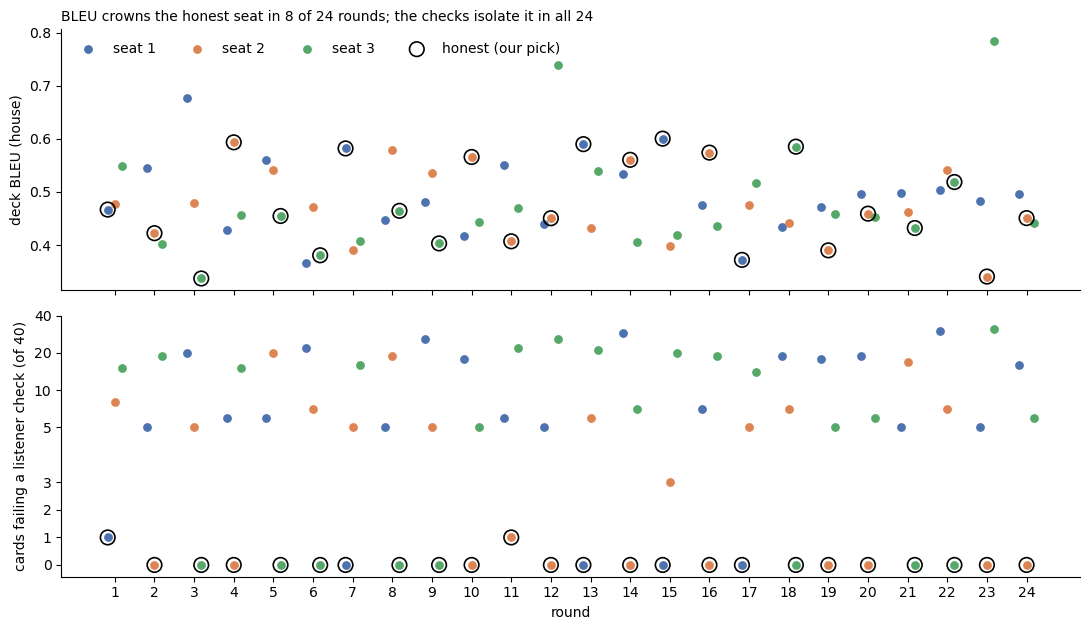

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
cols = {1: "#4C72B0", 2: "#DD8452", 3: "#55A868"}
b = decks.pivot(index="round", columns="seat", values="bleu")
for s in (1, 2, 3):
    off = (s - 2) * 0.18
    ax[0].scatter(b.index + off, b[s], color=cols[s], s=28, label=f"seat {s}")
    ax[1].scatter(fails.index + off, fails[s], color=cols[s], s=28)
hon = verdict.honest_seat
ax[0].scatter(hon.index + (hon - 2) * 0.18, [b.loc[r, s] for r, s in hon.items()], facecolors="none", edgecolors="k", s=110, lw=1.2, label="honest (our pick)")
ax[1].scatter(hon.index + (hon - 2) * 0.18, [fails.loc[r, s] for r, s in hon.items()], facecolors="none", edgecolors="k", s=110, lw=1.2)
ax[0].set_ylabel("deck BLEU (house)"); ax[0].legend(frameon=False, ncol=4, loc="upper left")
ax[1].set_ylabel("cards failing a listener check (of 40)"); ax[1].set_xlabel("round")
ax[1].set_yscale("symlog", linthresh=5); ax[1].set_yticks([0, 1, 2, 3, 5, 10, 20, 40]); ax[1].set_yticklabels([0, 1, 2, 3, 5, 10, 20, 40])
ax[1].set_xticks(range(1, 25))
for a in ax: a.spines[["top", "right"]].set_visible(False)
n_ok = int((verdict.honest_seat == verdict.bleu_winner).sum())
ax[0].set_title(f"BLEU crowns the honest seat in {n_ok} of 24 rounds; the checks isolate it in all 24", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig("separation.png", dpi=130)
print("BLEU picks the honest seat in", int((verdict.honest_seat == verdict.bleu_winner).sum()), "rounds")

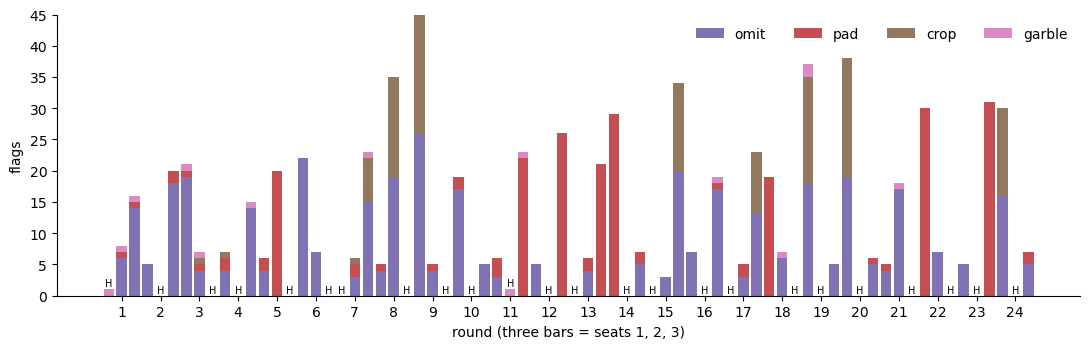

In [13]:
fig, ax = plt.subplots(figsize=(11, 3.6))
cnt = by_check[[f"f_{c}" for c in SCORE]].rename(columns=lambda c: c[2:])
cnt.index = [f"{r}.{s}" for r, s in cnt.index]
bottom = np.zeros(len(cnt))
for c, col in zip(SCORE, ["#8172B3", "#C44E52", "#937860", "#DA8BC3"]):
    ax.bar(range(len(cnt)), cnt[c], bottom=bottom, color=col, label=c, width=.8); bottom += cnt[c].values
ax.set_xticks(range(1, 72, 3)); ax.set_xticklabels(range(1, 25)); ax.set_xlabel("round (three bars = seats 1, 2, 3)")
ax.set_ylabel("flags"); ax.legend(frameon=False, ncol=4)
for i, (r, s) in enumerate(hon.items()):
    ax.text((r - 1) * 3 + s - 1, cnt.iloc[(r - 1) * 3 + s - 1].sum() + 0.5, "H", ha="center", fontsize=7)
ax.spines[["top", "right"]].set_visible(False); fig.tight_layout(); fig.savefig("tricks_by_deck.png", dpi=130)

## 6. Cross-checks

In [14]:
alt = pd.DataFrame({
    "all checks": verdict.honest_seat,
    "omit only (excl. padder)": card.assign(o=card.f_omit + 100 * (card.groupby(["round", "seat"]).f_pad.transform("sum") > 10))
                                    .groupby(["round", "seat"]).o.sum().unstack().idxmin(axis=1),
    "with wrong-fact check": card.assign(o=card.fails | card.f_wrong).groupby(["round", "seat"]).o.sum().unstack().idxmin(axis=1),
})
print(alt.T.to_string())
print("agree in every round:", bool((alt.nunique(axis=1) == 1).all()))

round                     1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23  24
all checks                 1   2   3   2   3   3   1   3   3   2   2   2   1   2   1   2   1   3   2   2   3   3   2   2
omit only (excl. padder)   1   2   3   2   3   3   1   3   3   2   2   2   1   2   1   2   1   3   2   2   3   3   2   2
with wrong-fact check      1   2   3   2   3   3   1   3   3   2   2   2   1   2   1   2   1   3   2   2   3   3   2   2
agree in every round: True


## 7. Verdict

In [15]:
seats = verdict.honest_seat.tolist()
print("honest seats:", seats)
print("digits      :", [s - 1 for s in seats])
print("word        :", decode(seats))
print("flag        : SIGMOID_" + decode(seats))
print("baseline    : SIGMOID_" + decode(bleu_pick), "(BLEU)")
print("smallest margin:", verdict.margin.min(), "cards, round(s)", verdict.index[verdict.margin == verdict.margin.min()].tolist())

honest seats: [1, 2, 3, 2, 3, 3, 1, 3, 3, 2, 2, 2, 1, 2, 1, 2, 1, 3, 2, 2, 3, 3, 2, 2]
digits      : [0, 1, 2, 1, 2, 2, 0, 2, 2, 1, 1, 1, 0, 1, 0, 1, 0, 2, 1, 1, 2, 2, 1, 1]
word        : FRINDLOW
flag        : SIGMOID_FRINDLOW
baseline    : SIGMOID_SKELDRAP (BLEU)
smallest margin: 3 cards, round(s) [15]


In every round one deck fails at most one card (a near-duplicate of a reference, or a clumsy sentence of the kind the references contain too); the other two fail on 3 to 31 cards. The closest call is round 15: 0 against 3. Each round has one heavy bluffer (8 croppers, 8 padders, 8 splicers) and one light bluffer that drops facts on 3-7 cards, sometimes with a padded card or a stutter. Splicing is caught less by the fluency check than by what it does to the content: stitched fragments lose facts and pick up unsupported ones, and splice decks have the highest share of bigrams never seen in any other card's references. BLEU picks the honest seat in 8 rounds out of 24.

The decoded word is not an English word. Neither is the BLEU word, so the words look like made-up tokens rather than dictionary words; the seat choices do not depend on that.